# Circuit Analysis

In [9]:
import numpy as np
import matplotlib.pyplot as plt

In [2]:
# initialize the variables
n = 6 # number of nodes
A = np.zeros((n, n)) # initialize the conductance matrix as zeros(n, n)
b = np.zeros(n) # initialize the source vector as zeros(n)
Rl = 0.01
Rh = 10
V = 1

## Full Solution

In [3]:
# iterate over the rows and columns of the matrix A
for i in range(n):          # i = row number
    for j in range(n):      # j = column number
        # fill in the diagonal elements of A with the sum of the conductances (1/R)
        if i == j:
            A[i, j] = 2/Rl + 1/Rh   # two cable pieces + one house

        # fill in the off-diagonal elements of A with the negative line conductances
        elif abs(i - j) == 1:
            A[i, j] = -1/Rl         # neighbouring houses linked by one cable piece

# fill in the final diagonal element of A with the sum of the conductances (1/R) but only 1 line conductance
A[n-1, n-1] = 1/Rl + 1/Rh           # last house: only one cable piece

# fill in the first element of the vector b with the voltage source divided by the line resistance
b[0] = V/Rl                         # only the first house is wired to the substation

# solve the system of equations Ax = b for x
x = np.linalg.solve(A, b)

print("A =")
print(A)
print("b =", b)
print("House voltages =", x)

A =
[[ 200.1 -100.     0.     0.     0.     0. ]
 [-100.   200.1 -100.     0.     0.     0. ]
 [   0.  -100.   200.1 -100.     0.     0. ]
 [   0.     0.  -100.   200.1 -100.     0. ]
 [   0.     0.     0.  -100.   200.1 -100. ]
 [   0.     0.     0.     0.  -100.   100.1]]
b = [100.   0.   0.   0.   0.   0.]
House voltages = [0.99408948 0.98917305 0.98524579 0.98230378 0.98034407 0.9793647 ]


## Approximate solution

[0.994 0.989 0.985 0.982 0.98  0.979]
Exact voltages = [0.99408948 0.98917305 0.98524579 0.98230378 0.98034407 0.9793647 ]
Approximate voltages = [0.994 0.989 0.985 0.982 0.98  0.979]
Table of exact, approximate, and difference:
Exact	Approx	Difference	Percentage Difference
0.994089	0.994000	0.000089	0.009001
0.989173	0.989000	0.000173	0.017494
0.985246	0.985000	0.000246	0.024947
0.982304	0.982000	0.000304	0.030925
0.980344	0.980000	0.000344	0.035097
0.979365	0.979000	0.000365	0.037239


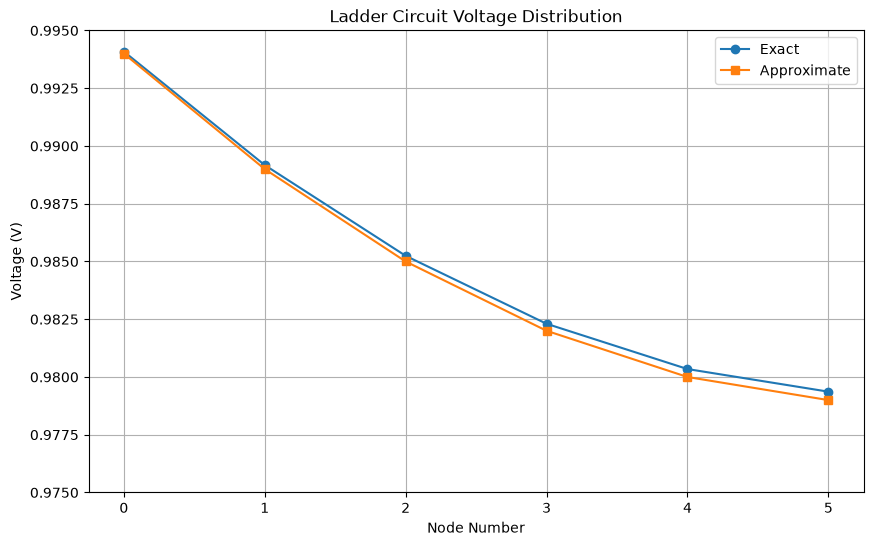

In [24]:
# TODO: calculate the current assuming no line resistance
I = V / Rh

# setup an array to hold the approximate voltage values
x_approx = np.zeros(n)

# TODO: calculate the approximate voltage values for each of the n nodes. A for loop might be helpful here
v_prev = V
for i in range(n):
    I_segment = (n - i) * I     # current through the segment feeding node i
    x_approx[i] = v_prev - Rl * I_segment
    v_prev = x_approx[i]

print(x_approx)

# compare approximate and exact values 
print("Exact voltages =", x)
print("Approximate voltages =", x_approx)

# difference in a table format
diff = x - x_approx
percentage_diff = (diff / x) * 100
table = np.vstack((x, x_approx, diff, percentage_diff)).T
print("Table of exact, approximate, and difference:")
print("Exact\tApprox\tDifference\tPercentage Difference")
for row in table:
    print("{:.6f}\t{:.6f}\t{:.6f}\t{:.6f}".format(row[0], row[1], row[2], row[3]))

# difference in a chart format (voltage vs node number)
plt.figure(figsize=(10, 6))
plt.plot(range(n), x, 'o-', label='Exact')
plt.plot(range(n), x_approx, 's-', label='Approximate')
plt.xlabel('Node Number')
plt.ylabel('Voltage (V)')
plt.title('Ladder Circuit Voltage Distribution')
plt.ylim(0.975, 0.995)
plt.legend()
plt.grid(True)
plt.show()
